# Plantar Thermography EDA — Physics-Informed GAT for Diabetic Foot Complications

**Notebook:** `02_eda.ipynb`
**Phase:** 3 — Exploratory Data Analysis

This notebook explores the two processed tables produced by `01_data_loading_integrity.ipynb`:

- `data/processed/manifest.csv` — one row per file (CSV/PNG, full-foot/angiosome).
- `data/processed/subject_metadata.csv` — one row per subject (167 rows), with per-region
  average temperatures and the existing Thermal Change Index (TCI) biomarker.

Per project convention, **this notebook does not re-parse the raw Excel file or walk the raw
`ThermoDataBase` directory** — those two processed CSVs are the single source of truth. The
only exception is Sections 8 and 9, which load a handful of individual raw thermogram CSVs
directly (their paths come from `manifest_df`) purely for visual inspection.

This notebook doubles as project documentation: every section below is preceded by a short
explanation of what it does and why it matters for the downstream GAT modeling work.

## Section 1: Setup

Load both processed tables (`manifest_df`, `metadata_df`), confirm their shapes and dtypes
loaded as expected, and fix a **consistent color scheme for the whole notebook**:
`Control = blue`, `DM = orange/red`. Every group-comparison plot from here on reuses this
mapping so the visual language stays consistent throughout the notebook and any figures
pulled into the paper.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

# ---- Paths (processed tables are the single source of truth from here on) ----
PROCESSED_DIR = Path("data/processed")
MANIFEST_PATH = PROCESSED_DIR / "manifest.csv"
METADATA_PATH = PROCESSED_DIR / "subject_metadata.csv"

# ---- Consistent color scheme for the whole notebook ----
GROUP_COLORS = {"Control": "#1f77b4", "DM": "#ff7f0e"}  # Control = blue, DM = orange/red
GROUP_ORDER = ["Control", "DM"]

print("=== SECTION 1: Setup ===")

manifest_df = pd.read_csv(MANIFEST_PATH)
metadata_df = pd.read_csv(METADATA_PATH)

print(f"manifest_df shape: {manifest_df.shape}")
print(f"metadata_df shape: {metadata_df.shape}")

print("\nmanifest_df dtypes:")
print(manifest_df.dtypes)

print("\nmetadata_df dtypes:")
print(metadata_df.dtypes)

print("\nmanifest_df head:")
print(manifest_df.head())

print("\nmetadata_df head:")
print(metadata_df.head())


=== SECTION 1: Setup ===
manifest_df shape: (3340, 9)
metadata_df shape: (167, 19)

manifest_df dtypes:
group            str
subject_id       str
gender           str
foot_side        str
is_angiosome    bool
region           str
file_type        str
file_stem        str
file_path        str
dtype: object

metadata_df dtypes:
Subject              str
Gender               str
Age_years        float64
Weight_kg        float64
Height_m         float64
BMI              float64
RIGHT_General    float64
RIGHT_LCA        float64
RIGHT_LPA        float64
RIGHT_MCA        float64
RIGHT_MPA        float64
RIGHT_TCI        float64
LEFT_General     float64
LEFT_LCA         float64
LEFT_LPA         float64
LEFT_MCA         float64
LEFT_MPA         float64
LEFT_TCI         float64
Group                str
dtype: object

manifest_df head:
     group subject_id gender foot_side  is_angiosome region file_type  \
0  Control      CG001      M         L         False    NaN       csv   
1  Control      CG

## Section 2: Group Balance

Confirm the Control/DM class split and check whether Gender is evenly distributed across
groups. An uneven Gender/Group association would be a confound worth stratifying on later,
so we test it formally with a chi-square test of independence rather than eyeballing the bars.

=== SECTION 2: Group Balance ===


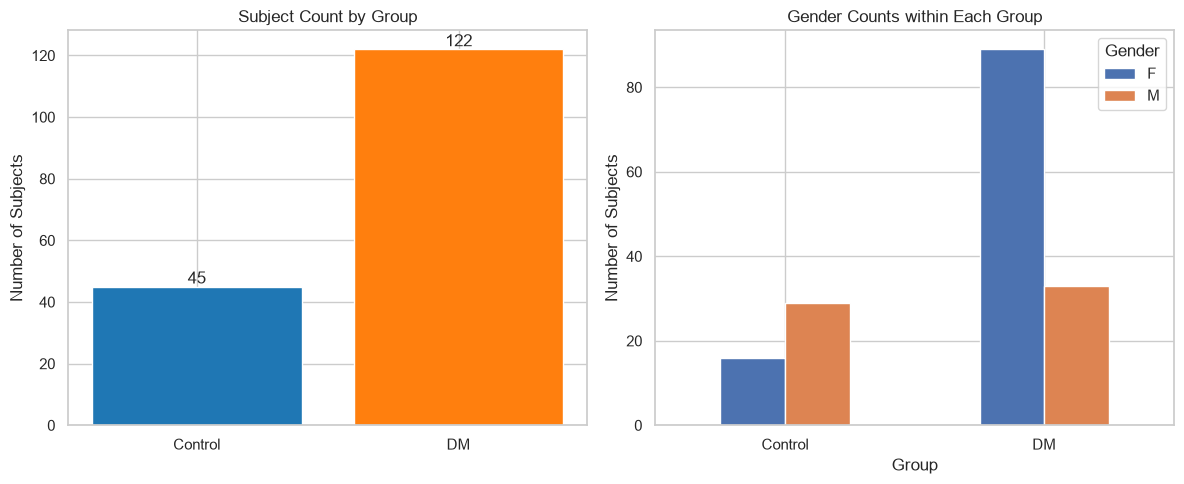


Contingency table:
Gender    F   M
Group          
Control  16  29
DM       89  33

Chi-square statistic: 18.1249, dof: 1, p-value: 0.0000
Interpretation: Gender distribution significantly differs between Control and DM groups -- consider stratifying by Gender in later splits/analyses.


In [3]:
print("=== SECTION 2: Group Balance ===")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Subject counts by Group
group_counts = metadata_df["Group"].value_counts().reindex(GROUP_ORDER)
axes[0].bar(group_counts.index, group_counts.values,
            color=[GROUP_COLORS[g] for g in group_counts.index])
axes[0].set_title("Subject Count by Group")
axes[0].set_ylabel("Number of Subjects")
for i, v in enumerate(group_counts.values):
    axes[0].text(i, v + 1, str(int(v)), ha="center")

# Gender counts within each Group (grouped bar chart)
gender_group = (
    metadata_df.groupby(["Group", "Gender"]).size().unstack(fill_value=0).reindex(GROUP_ORDER)
)
gender_group.plot(kind="bar", ax=axes[1], color=["#4c72b0", "#dd8452"])
axes[1].set_title("Gender Counts within Each Group")
axes[1].set_ylabel("Number of Subjects")
axes[1].set_xlabel("Group")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Gender")

plt.tight_layout()
plt.show()

# Chi-square test of independence: Gender vs Group
contingency = pd.crosstab(metadata_df["Group"], metadata_df["Gender"])
chi2, p_value, dof, expected = stats.chi2_contingency(contingency)

print(f"\nContingency table:\n{contingency}")
print(f"\nChi-square statistic: {chi2:.4f}, dof: {dof}, p-value: {p_value:.4f}")
if p_value < 0.05:
    print("Interpretation: Gender distribution significantly differs between Control and DM "
          "groups -- consider stratifying by Gender in later splits/analyses.")
else:
    print("Interpretation: No significant association between Gender and Group -- "
          "Gender is reasonably balanced across the two groups.")


## Section 3: Demographic Comparison (Age, Weight, Height, BMI)

Compare Control vs DM on the four basic demographic variables. These are the most likely
confounders: if DM subjects are systematically older or heavier than Controls, a model could
learn to separate the groups from demographics rather than from true thermal pathology signal.
We use the **Mann-Whitney U test** rather than a t-test since it doesn't assume the variables
are normally distributed, and flag any variable with p < 0.05 explicitly.

=== SECTION 3: Demographic Comparison ===


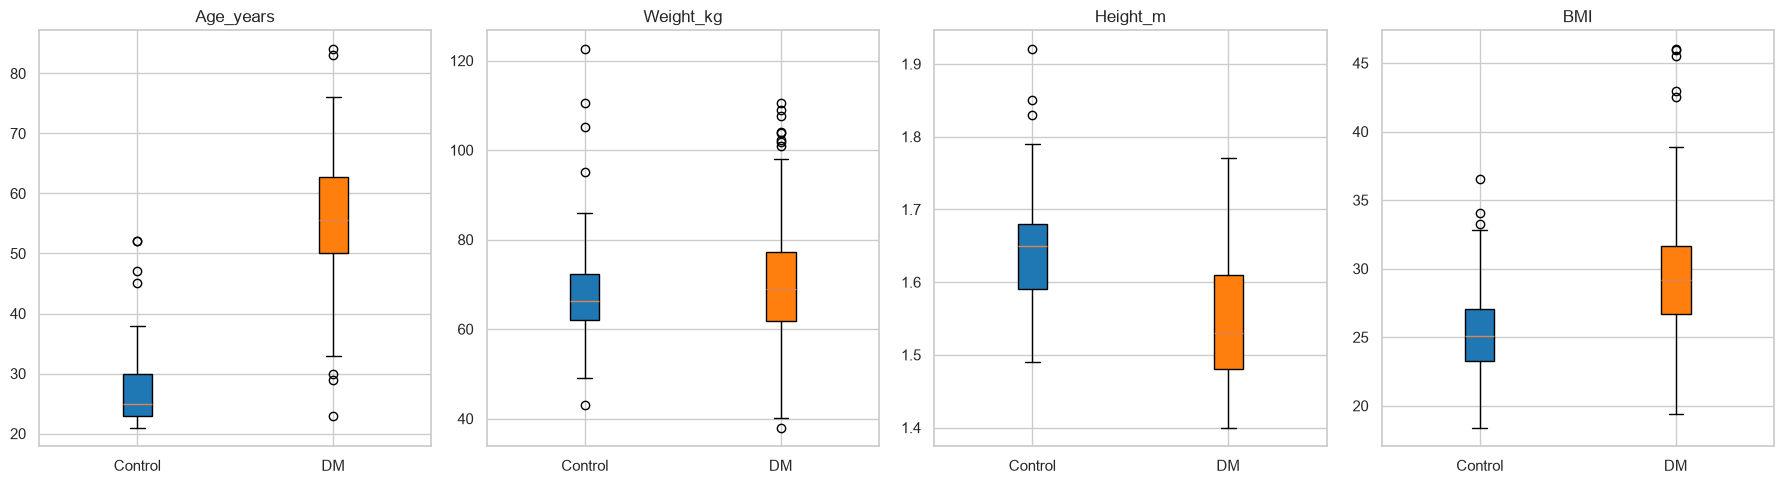


--- Age_years ---
              mean  median        std   min   max
Group                                            
Control  27.755556    25.0   8.185785  21.0  52.0
DM       55.983607    55.5  10.613405  23.0  84.0
Mann-Whitney U test: U=170.00, p=0.0000
**FLAG: Groups differ significantly in Age_years (p=0.0000) -- this is a potential confounder the model could learn instead of true pathology signal, and should be discussed in the paper's limitations section.**

--- Weight_kg ---
              mean  median        std   min    max
Group                                             
Control  69.486667    66.3  14.945364  43.0  122.5
DM       71.140206    69.0  14.994740  38.0  110.5
Mann-Whitney U test: U=1958.50, p=0.3270

--- Height_m ---
             mean  median       std   min   max
Group                                          
Control  1.649333    1.65  0.091488  1.49  1.92
DM       1.546737    1.53  0.088190  1.40  1.77
Mann-Whitney U test: U=3374.00, p=0.0000
**FLAG: Groups

In [4]:
print("=== SECTION 3: Demographic Comparison ===")

demo_vars = ["Age_years", "Weight_kg", "Height_m", "BMI"]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, var in zip(axes, demo_vars):
    data_by_group = [metadata_df.loc[metadata_df["Group"] == g, var].dropna() for g in GROUP_ORDER]
    bp = ax.boxplot(data_by_group, tick_labels=GROUP_ORDER, patch_artist=True)
    for patch, g in zip(bp["boxes"], GROUP_ORDER):
        patch.set_facecolor(GROUP_COLORS[g])
    ax.set_title(var)
plt.tight_layout()
plt.show()

for var in demo_vars:
    print(f"\n--- {var} ---")
    summary = (
        metadata_df.groupby("Group")[var]
        .agg(["mean", "median", "std", "min", "max"])
        .reindex(GROUP_ORDER)
    )
    print(summary)

    control_vals = metadata_df.loc[metadata_df["Group"] == "Control", var].dropna()
    dm_vals = metadata_df.loc[metadata_df["Group"] == "DM", var].dropna()
    u_stat, p_value = stats.mannwhitneyu(control_vals, dm_vals, alternative="two-sided")
    print(f"Mann-Whitney U test: U={u_stat:.2f}, p={p_value:.4f}")

    if p_value < 0.05:
        print(f"**FLAG: Groups differ significantly in {var} (p={p_value:.4f}) -- this is a "
              f"potential confounder the model could learn instead of true pathology signal, "
              f"and should be discussed in the paper's limitations section.**")


## Section 4: TCI Comparison (the core existing biomarker)

TCI (Thermal Change Index) is the existing literature metric this project's GAT-based
approach needs to explain or improve upon. Violin plots show the full distribution shape
(not just quartiles), and the Mann-Whitney U test plus IQR overlap tell us how cleanly TCI
already separates Control from DM — i.e. how high the bar is for a new model to clear.

=== SECTION 4: TCI Comparison ===


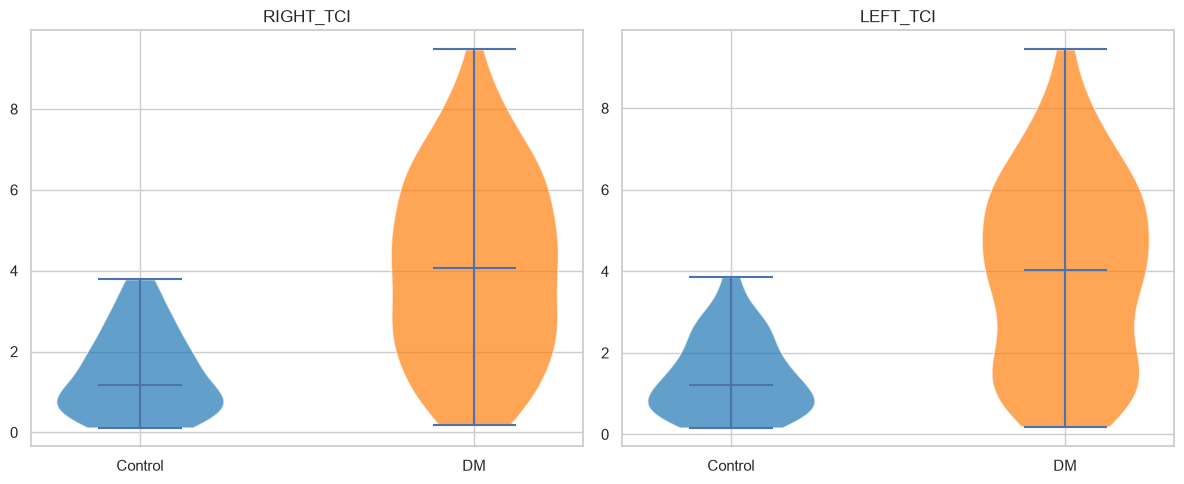


--- RIGHT_TCI ---
Mann-Whitney U test: U=846.00, p=0.0000
Control IQR (25th-75th pct): [0.656, 1.973]
DM IQR (25th-75th pct): [2.186, 5.917]
IQRs do not overlap -- distributions separate cleanly on this metric.

--- LEFT_TCI ---
Mann-Whitney U test: U=960.00, p=0.0000
Control IQR (25th-75th pct): [0.699, 2.089]
DM IQR (25th-75th pct): [1.805, 5.806]
IQRs overlap by 0.284 -- distributions are not cleanly separated on this metric alone.


In [5]:
print("=== SECTION 4: TCI Comparison ===")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, ["RIGHT_TCI", "LEFT_TCI"]):
    plot_data = [metadata_df.loc[metadata_df["Group"] == g, col].dropna() for g in GROUP_ORDER]
    parts = ax.violinplot(plot_data, showmedians=True)
    for pc, g in zip(parts["bodies"], GROUP_ORDER):
        pc.set_facecolor(GROUP_COLORS[g])
        pc.set_alpha(0.7)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(GROUP_ORDER)
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in ["RIGHT_TCI", "LEFT_TCI"]:
    print(f"\n--- {col} ---")
    control_vals = metadata_df.loc[metadata_df["Group"] == "Control", col].dropna()
    dm_vals = metadata_df.loc[metadata_df["Group"] == "DM", col].dropna()

    u_stat, p_value = stats.mannwhitneyu(control_vals, dm_vals, alternative="two-sided")
    print(f"Mann-Whitney U test: U={u_stat:.2f}, p={p_value:.4f}")

    c_25, c_75 = np.percentile(control_vals, [25, 75])
    d_25, d_75 = np.percentile(dm_vals, [25, 75])
    print(f"Control IQR (25th-75th pct): [{c_25:.3f}, {c_75:.3f}]")
    print(f"DM IQR (25th-75th pct): [{d_25:.3f}, {d_75:.3f}]")

    overlap = min(c_75, d_75) - max(c_25, d_25)
    if overlap > 0:
        print(f"IQRs overlap by {overlap:.3f} -- distributions are not cleanly separated on "
              f"this metric alone.")
    else:
        print("IQRs do not overlap -- distributions separate cleanly on this metric.")


## Section 5: Per-Region Temperature Comparison

Break the General/angiosome temperature comparison down by foot side and specific region.
This is the first look at *which* angiosome regions drive the Control-vs-DM difference —
important later for interpretability claims about the GAT's attention over angiosome nodes.

=== SECTION 5: Per-Region Temperature Comparison ===


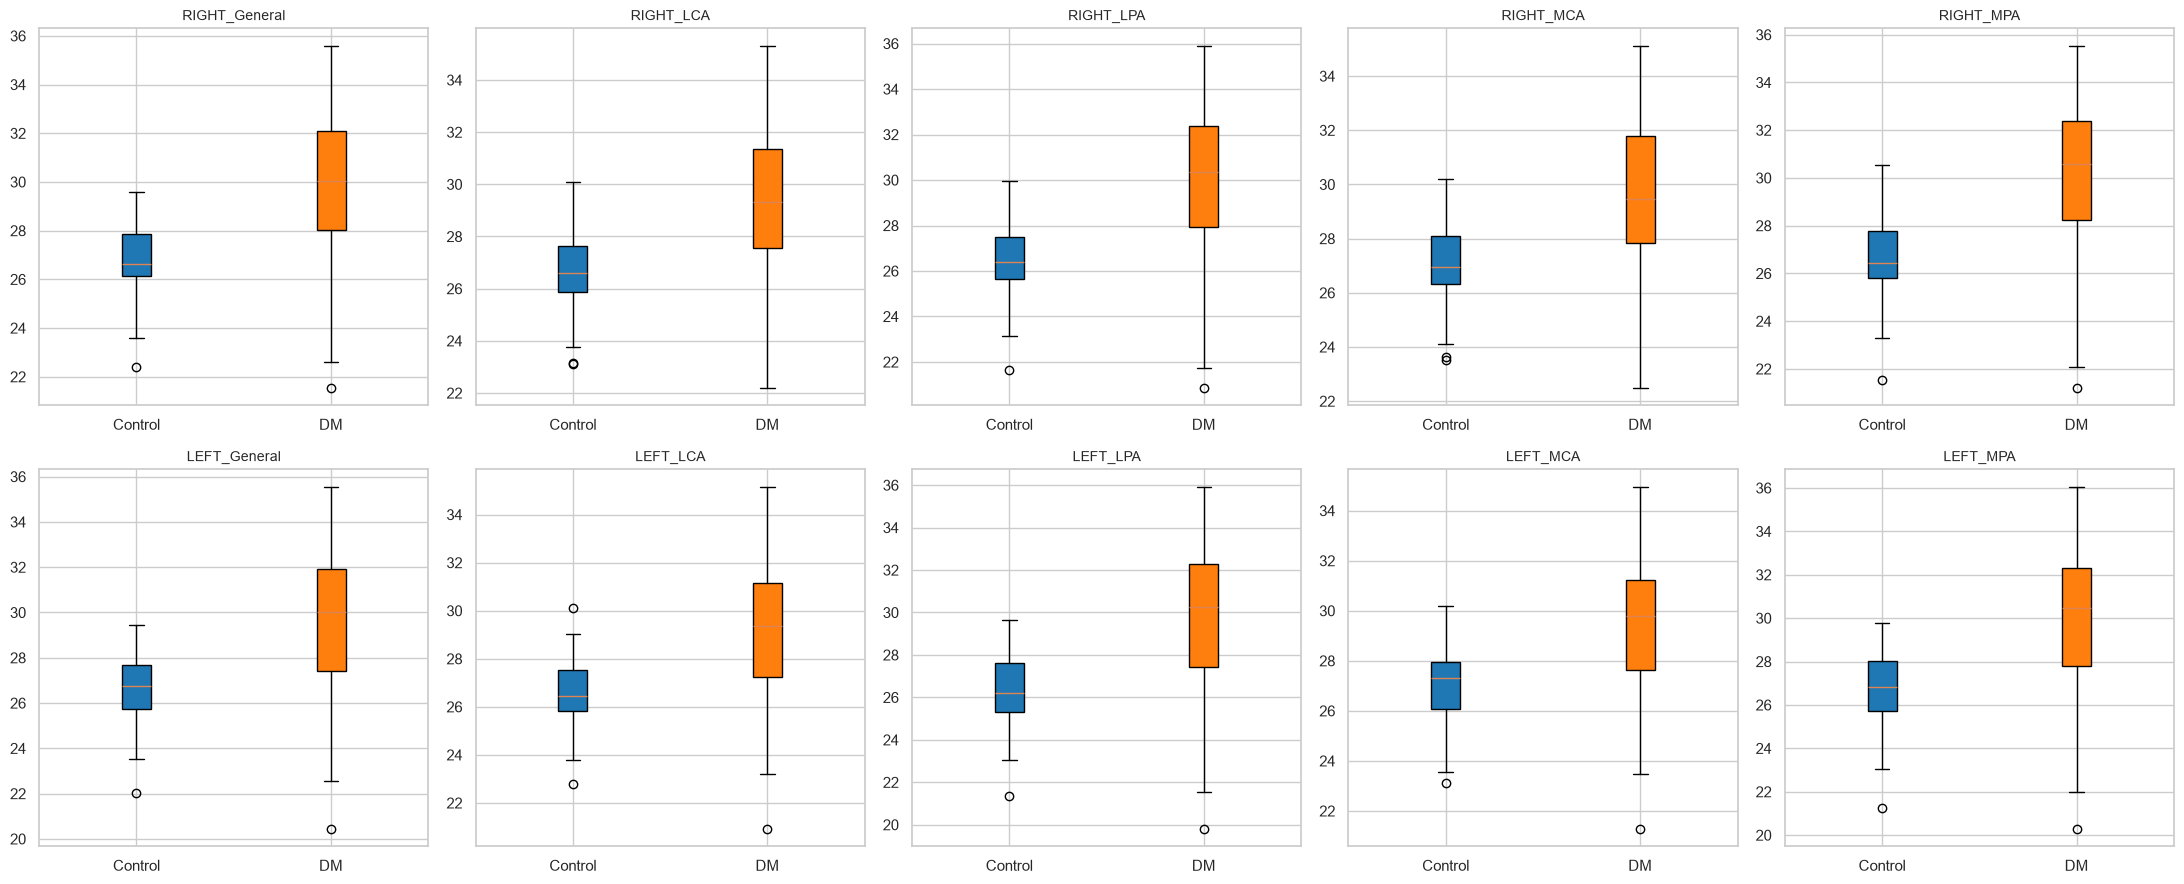

In [6]:
print("=== SECTION 5: Per-Region Temperature Comparison ===")

regions = ["General", "LCA", "LPA", "MCA", "MPA"]
foot_sides = ["RIGHT", "LEFT"]

fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for row, side in enumerate(foot_sides):
    for col, region in enumerate(regions):
        var = f"{side}_{region}"
        ax = axes[row, col]
        data_by_group = [metadata_df.loc[metadata_df["Group"] == g, var].dropna() for g in GROUP_ORDER]
        bp = ax.boxplot(data_by_group, tick_labels=GROUP_ORDER, patch_artist=True)
        for patch, g in zip(bp["boxes"], GROUP_ORDER):
            patch.set_facecolor(GROUP_COLORS[g])
        ax.set_title(var, fontsize=10)

plt.tight_layout()
plt.show()


## Section 6: Left-Right Foot Symmetry Analysis

Diabetic neuropathy literature often reports asymmetric presentation between feet. Here we
compute each subject's absolute L/R difference in General temperature and test whether DM
subjects show more asymmetry than Controls.

=== SECTION 6: Left-Right Foot Symmetry Analysis ===


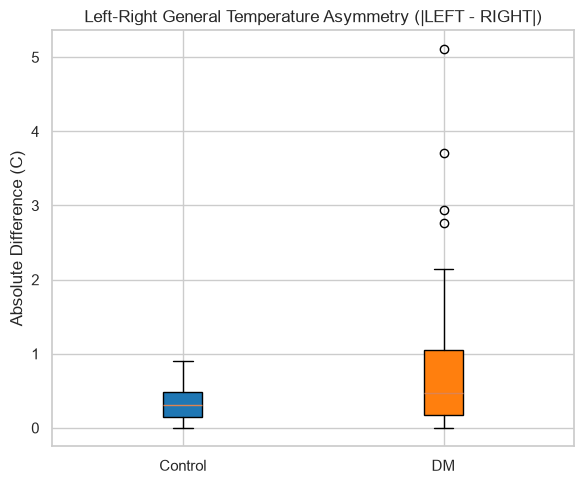

Control mean asymmetry: 0.316 C (median 0.315 C)
DM mean asymmetry: 0.711 C (median 0.476 C)
Mann-Whitney U test: U=1925.00, p=0.0031
Interpretation: DM subjects show significantly greater L/R asymmetry than Controls, consistent with diabetic neuropathy literature reporting asymmetric presentation.


In [7]:
print("=== SECTION 6: Left-Right Foot Symmetry Analysis ===")

metadata_df["LR_asymmetry"] = (metadata_df["LEFT_General"] - metadata_df["RIGHT_General"]).abs()

fig, ax = plt.subplots(figsize=(6, 5))
data_by_group = [metadata_df.loc[metadata_df["Group"] == g, "LR_asymmetry"].dropna() for g in GROUP_ORDER]
bp = ax.boxplot(data_by_group, tick_labels=GROUP_ORDER, patch_artist=True)
for patch, g in zip(bp["boxes"], GROUP_ORDER):
    patch.set_facecolor(GROUP_COLORS[g])
ax.set_title("Left-Right General Temperature Asymmetry (|LEFT - RIGHT|)")
ax.set_ylabel("Absolute Difference (C)")
plt.tight_layout()
plt.show()

control_asym = metadata_df.loc[metadata_df["Group"] == "Control", "LR_asymmetry"].dropna()
dm_asym = metadata_df.loc[metadata_df["Group"] == "DM", "LR_asymmetry"].dropna()
u_stat, p_value = stats.mannwhitneyu(control_asym, dm_asym, alternative="two-sided")

print(f"Control mean asymmetry: {control_asym.mean():.3f} C "
      f"(median {control_asym.median():.3f} C)")
print(f"DM mean asymmetry: {dm_asym.mean():.3f} C (median {dm_asym.median():.3f} C)")
print(f"Mann-Whitney U test: U={u_stat:.2f}, p={p_value:.4f}")

if p_value < 0.05:
    if dm_asym.mean() > control_asym.mean():
        print("Interpretation: DM subjects show significantly greater L/R asymmetry than "
              "Controls, consistent with diabetic neuropathy literature reporting asymmetric "
              "presentation.")
    else:
        print("Interpretation: The difference is significant, but Control asymmetry is higher "
              "than DM -- this runs counter to the typical neuropathy asymmetry narrative and "
              "is worth a closer look before writing it up.")
else:
    print("Interpretation: No significant difference in L/R asymmetry between Control and DM "
          "groups on this measure.")


## Section 7: Correlation Heatmap

A full correlation matrix across demographics and all 12 region/TCI temperature columns.
Useful for spotting redundant features (near-perfect correlations) or surprising
disconnects before designing the feature set for later modeling phases.

=== SECTION 7: Correlation Heatmap ===


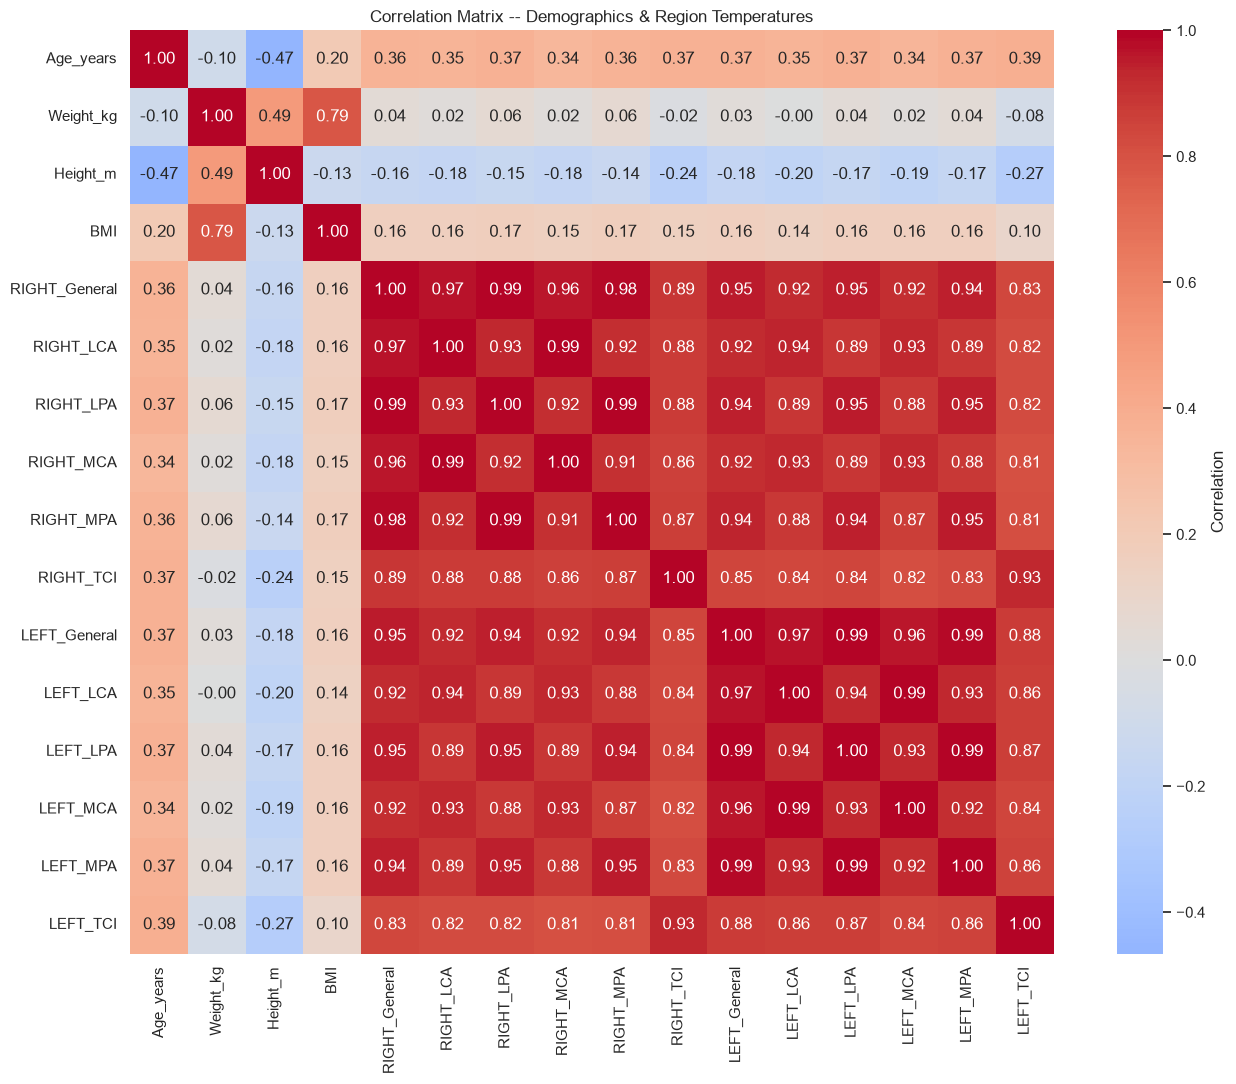

In [8]:
print("=== SECTION 7: Correlation Heatmap ===")

numeric_cols = [
    "Age_years", "Weight_kg", "Height_m", "BMI",
    "RIGHT_General", "RIGHT_LCA", "RIGHT_LPA", "RIGHT_MCA", "RIGHT_MPA", "RIGHT_TCI",
    "LEFT_General", "LEFT_LCA", "LEFT_LPA", "LEFT_MCA", "LEFT_MPA", "LEFT_TCI",
]

corr_matrix = metadata_df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax,
    square=True, cbar_kws={"label": "Correlation"},
)
ax.set_title("Correlation Matrix -- Demographics & Region Temperatures")
plt.tight_layout()
plt.show()


**Notes on the correlation matrix (from the current dataset):**

- **Within-foot regions are highly redundant.** General/LCA/LPA/MCA/MPA on the same foot
  correlate at r ≈ 0.95-0.99 with each other (e.g. RIGHT_LPA vs RIGHT_MPA ≈ 0.99). Each
  angiosome is tracking the same overall foot-temperature signal far more than it's tracking
  anything region-specific — worth keeping in mind so the GAT isn't just re-learning five
  near-duplicate node features per foot.
- **Left and right feet also correlate strongly with each other** (RIGHT_General vs
  LEFT_General ≈ 0.95), which is expected physiologically but means most of the per-region
  variance is "foot temperature level," not region- or side-specific pattern.
- **Weight_kg is the odd one out** — it barely correlates with anything (|r| < 0.06 against
  every region/TCI column), unlike Height, BMI, and especially Age, which all correlate more
  meaningfully with region temperatures.
- **Age_years correlates moderately and consistently with every region and TCI column**
  (r ≈ 0.34-0.39, all positive) — given Section 3 already flags Age as a strong Control/DM
  confounder, this is worth watching closely: some of the apparent group separation in
  temperature/TCI could be partly an age effect rather than a pure diabetes effect.
- **Height_m correlates negatively with Age** (r ≈ -0.47) in this cohort, on top of both being
  flagged as confounders individually — they're not fully independent axes of variation
  between groups.

## Section 8: Raw Thermogram Visual Inspection

Sanity-check the aggregated metadata numbers against the actual raw thermal images.
Randomly sample 2 Control and 2 DM subjects (fixed seed for reproducibility), load each
one's full-foot **left** raw CSV via `manifest_df`, mask background (0) as NaN per the
dataset's official visualization convention, and plot side by side.

=== SECTION 8: Raw Thermogram Visual Inspection ===
Selected subjects (seed=42): ['CG004', 'CG035', 'DM054', 'DM053']


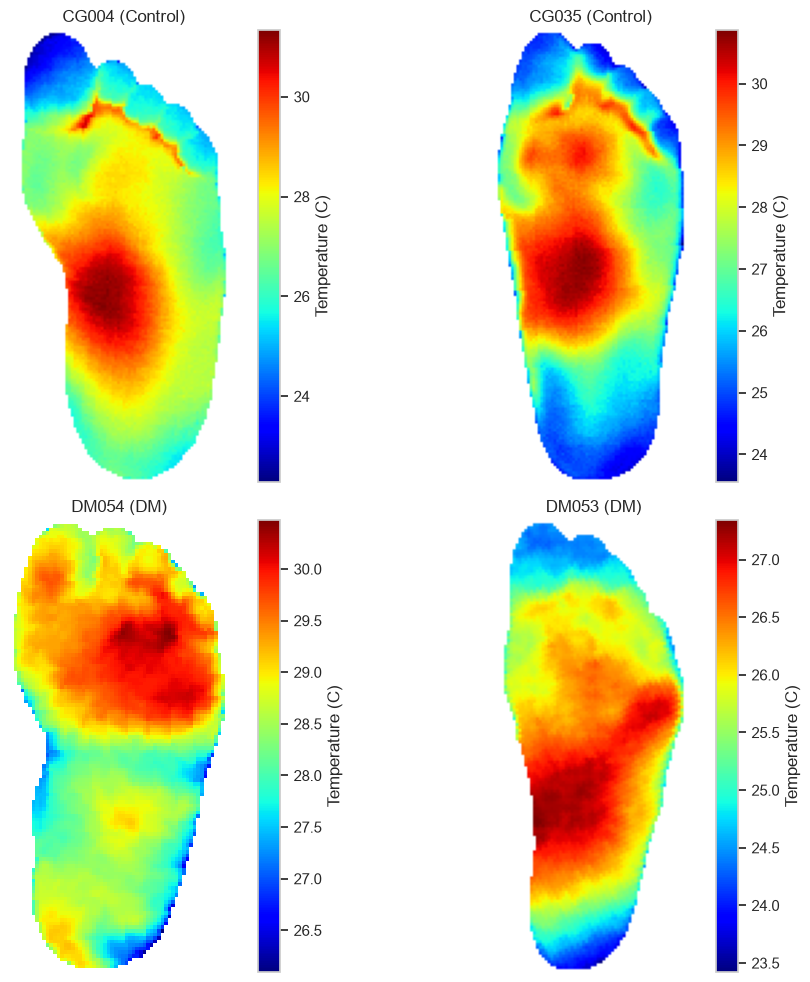

In [9]:
print("=== SECTION 8: Raw Thermogram Visual Inspection ===")

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

control_subjects = metadata_df.loc[metadata_df["Group"] == "Control", "Subject"].unique()
dm_subjects = metadata_df.loc[metadata_df["Group"] == "DM", "Subject"].unique()

sample_control = rng.choice(control_subjects, size=2, replace=False)
sample_dm = rng.choice(dm_subjects, size=2, replace=False)
sample_subjects = list(sample_control) + list(sample_dm)

print(f"Selected subjects (seed={RANDOM_SEED}): {sample_subjects}")


def find_full_foot_csv(subject_id, foot_side, manifest_df):
    """Look up the full-foot (non-angiosome) raw CSV path for a subject/foot side."""
    match = manifest_df[
        (manifest_df["subject_id"] == subject_id)
        & (manifest_df["foot_side"] == foot_side)
        & (manifest_df["is_angiosome"] == False)
        & (manifest_df["file_type"] == "csv")
    ]
    if match.empty:
        raise FileNotFoundError(
            f"No full-foot CSV found for subject={subject_id}, side={foot_side}"
        )
    return Path(match.iloc[0]["file_path"])


def load_masked_grid(file_path):
    """Load a raw temperature grid CSV, masking background (0) as NaN."""
    grid = np.loadtxt(file_path, delimiter=",")
    return np.where(grid == 0, np.nan, grid)


fig, axes = plt.subplots(2, 2, figsize=(11, 10))
axes = axes.ravel()

for ax, subject_id in zip(axes, sample_subjects):
    group = metadata_df.loc[metadata_df["Subject"] == subject_id, "Group"].values[0]
    csv_path = find_full_foot_csv(subject_id, "L", manifest_df)
    grid = load_masked_grid(csv_path)

    im = ax.imshow(grid, cmap="jet")
    ax.set_title(f"{subject_id} ({group})")
    ax.axis("off")
    fig.colorbar(im, ax=ax, label="Temperature (C)")

plt.tight_layout()
plt.show()


## Section 9: Angiosome Region Spatial Layout

First visual confirmation of how the four plantar angiosomes (LCA, LPA, MCA, MPA) sit
relative to each other on the foot. For one sample Control subject, build a labeled array
(0 = background, 1-4 = each angiosome) from the four angiosome CSVs and overlay it as a
discrete-color map. This spatial layout directly informs how angiosome graph edges should be
defined in the GAT design.

=== SECTION 9: Angiosome Region Spatial Layout ===
Sample subject for angiosome layout: CG001


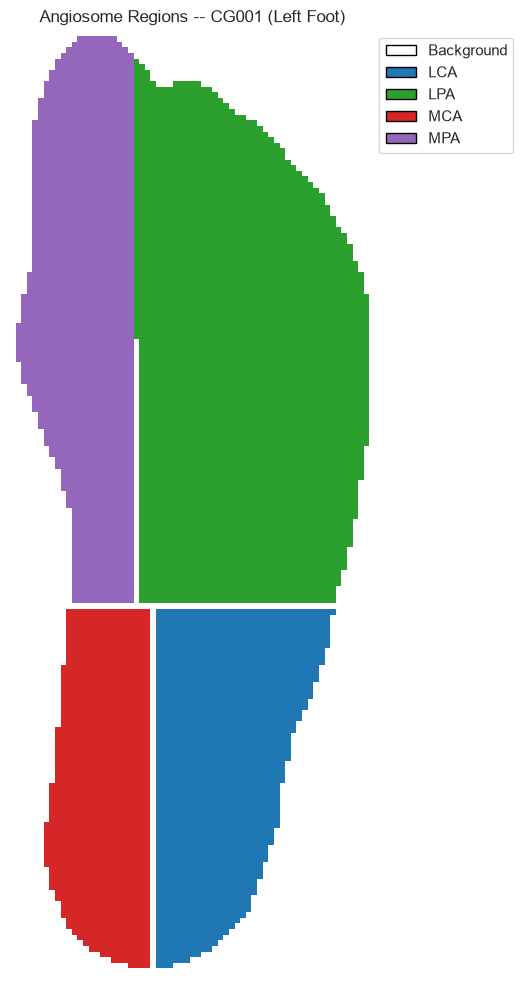

In [10]:
print("=== SECTION 9: Angiosome Region Spatial Layout ===")

sample_subject = metadata_df.loc[metadata_df["Group"] == "Control", "Subject"].iloc[0]
print(f"Sample subject for angiosome layout: {sample_subject}")

full_foot_path = find_full_foot_csv(sample_subject, "L", manifest_df)
full_grid_raw = np.loadtxt(full_foot_path, delimiter=",")

region_labels = {"LCA": 1, "LPA": 2, "MCA": 3, "MPA": 4}
labeled_array = np.zeros_like(full_grid_raw, dtype=int)

for region, label in region_labels.items():
    match = manifest_df[
        (manifest_df["subject_id"] == sample_subject)
        & (manifest_df["foot_side"] == "L")
        & (manifest_df["is_angiosome"] == True)
        & (manifest_df["region"] == region)
        & (manifest_df["file_type"] == "csv")
    ]
    if match.empty:
        raise FileNotFoundError(f"No angiosome CSV found for region={region}, subject={sample_subject}")
    region_path = Path(match.iloc[0]["file_path"])
    region_grid = np.loadtxt(region_path, delimiter=",")
    labeled_array[region_grid != 0] = label

cmap_colors = ["white", "#1f77b4", "#2ca02c", "#d62728", "#9467bd"]  # bg, LCA, LPA, MCA, MPA
region_cmap = ListedColormap(cmap_colors)

fig, ax = plt.subplots(figsize=(7, 10))
ax.imshow(labeled_array, cmap=region_cmap, vmin=0, vmax=4)
ax.set_title(f"Angiosome Regions -- {sample_subject} (Left Foot)")
ax.axis("off")

legend_labels = ["Background", "LCA", "LPA", "MCA", "MPA"]
legend_handles = [
    Patch(facecolor=c, edgecolor="black", label=l)
    for c, l in zip(cmap_colors, legend_labels)
]
ax.legend(handles=legend_handles, loc="upper right", bbox_to_anchor=(1.4, 1))

plt.tight_layout()
plt.show()


## Key EDA Findings (fill in after review)

- **Demographic confounders:** which of Age/Weight/Height/BMI differed significantly
  between Control and DM (Section 3)?
- **TCI signal strength:** how cleanly does existing TCI separate Control vs DM (Section 4)?
- **Angiosome regions with largest Control-vs-DM differences:** which region(s) stood out
  in Section 5?
- **L/R asymmetry:** did DM subjects show more asymmetry than Controls (Section 6)?
- **Other patterns worth carrying into preprocessing/modeling:** (e.g. correlation
  redundancies from Section 7, anything notable from the raw thermogram inspection in
  Section 8-9)


## Key EDA Findings

- **Demographic confounders identified**: Age (p<0.0001), Height (p<0.0001), 
  and BMI (p<0.0001) all differ significantly between Control and DM groups. 
  Height difference is likely secondary to the gender imbalance between 
  groups (DM group is 73% female vs. Control's 36% female) rather than a 
  direct diabetes effect. Age and BMI differences are clinically expected 
  (diabetes risk correlates with both) but remain genuine confounders that 
  must be acknowledged in the paper's limitations and controlled for via 
  stratified splitting.

- **TCI (existing literature biomarker) provides partial separation only**: 
  Right foot TCI cleanly separates Control from DM (non-overlapping IQRs). 
  Left foot TCI overlaps by 0.28 between group IQRs -- not a fully reliable 
  single-number diagnostic per foot. This motivates a more spatially-aware, 
  uncertainty-calibrated approach as a genuine improvement over the existing 
  metric, not just a re-implementation of it.

- **No single angiosome region cleanly separates the groups** -- DM runs 
  hotter and more variable across all 5 regions (General + 4 angiosomes) on 
  both feet, but with real overlap in every region. Diagnostic signal 
  appears distributed across regions rather than concentrated in one, 
  supporting a multi-region/graph-based approach over a single-feature 
  classifier.

- **L/R foot asymmetry is a strong, clean signal**: DM subjects show 
  significantly greater left-right temperature asymmetry than Controls 
  (0.711 C vs 0.316 C mean, p=0.003), consistent with the asymmetric 
  presentation of diabetic neuropathy in the literature. Candidate 
  engineered feature / graph-edge property for later phases.

- **Region temperatures are highly collinear (r=0.81-0.99 across all 12 
  region columns)** -- raw absolute region-average temperature carries 
  substantial redundant information across regions. This is architecturally 
  important: it supports prioritizing relative/differential features (like 
  TCI, or graph-relative node features) over raw absolute temperatures as 
  primary model inputs, since raw averages alone would offer limited 
  independent signal per region.

- **Visual inspection reveals qualitative spatial pattern differences not 
  captured by any single statistic**: Control feet show a smooth, 
  physiologically expected cool-toe-to-warm-heel gradient. DM feet show 
  loss of this gradient (diffuse, patchy heat) and/or off-center asymmetric 
  hot spots. This is strong qualitative motivation for a spatially-aware 
  (graph/CNN-based) architecture over simple average-temperature 
  classifiers, and these sample images are strong candidates for inclusion 
  as motivating figures in the final report/paper.

- **Angiosome spatial layout confirmed as a natural 2x2 grid**: LPA 
  (lateral-forefoot) | MPA (medial-forefoot) over LCA (lateral-heel) | MCA 
  (medial-heel). Direct anatomical adjacencies: LCA-LPA, LPA-MPA, MPA-MCA, 
  MCA-LCA (a 4-cycle). Diagonal adjacencies (LCA-MPA, LPA-MCA) are a design 
  choice for Phase 6's graph construction, not an anatomical given.